# Social dimensions of Eaton and Palisades fires

Author: Emalia Partlow

In [1]:
import pandas as pd
import geopandas as gpd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Import boundary data for the Eaton fire
eaton = gpd.read_file('data/Eaton_Perimeter_20250121/Eaton_Perimeter_20250121.shp') 
eaton

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08T00:00:00Z,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((-118.10093 34.16680, -118.1008..."


In [3]:
# Import boundary data for the Palisades fire
palisades = gpd.read_file('data/Palisades_Perimieter_20250121/Palisades_Perimieter_20250121.shp') 
palisades

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NA,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Are,Shape__Len,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07T00:00:00Z,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((-118.51974 34.02996, -118.5198..."


In [4]:
# Import eji data 
eji = gpd.read_file('data/EJI_2024_California/EJI_2024_California.gdb') 
eji.head(3)

,OBJECTID,STATEFP,COUNTYFP,TRACTCE,AFFGEOID,GEOID,GEOID_2020,COUNTY,StateDesc,STATEABBR,...,TWOMORE,E_TWOMORE,OTHERRACE,E_OTHERRACE,Tribe_PCT_Tract,Tribe_Names,Tribe_Flag,Shape_Length,Shape_Area,geometry
0,11620,06,077,005127,140000US06077005127,06077005127,06077005127,San Joaquin County,California,CA,...,408.0,5.4,0.0,0.0,0.0,-999,-999,5909.703135,1.962577e+06,"MULTIPOLYGON (((-2178538.439 328974.247, -2178..."
1,11557,06,077,003406,140000US06077003406,06077003406,06077003406,San Joaquin County,California,CA,...,203.0,5.4,0.0,0.0,0.0,-999,-999,3805.322542,8.541741e+05,"MULTIPOLYGON (((-2174646.947 350500.600, -2174..."
2,11594,06,077,004402,140000US06077004402,06077004402,06077004402,San Joaquin County,California,CA,...,132.0,2.2,0.0,0.0,0.0,-999,-999,8576.416378,4.345421e+06,"MULTIPOLYGON (((-2169306.156 358323.611, -2169..."


In [5]:
# Import eji data dictionary
eji_dictionary = pd.read_csv('data/EJI_2024_California/EJI_DATADICTIONARY_2024.csv',
                             skiprows=1, # Skip the first row of the file
                             encoding='cp1252') # The file uses Windows text encoding
eji_dictionary.head(3)

,2024 VARIABLE NAME,2022 VARIABLE NAME,2024 VARIABLE DESCRIPTION,MODULE,DOMAIN,DATA SOURCE,2024 TABLE FIELD CALCULATION,NOTES
0,STATEFP,STATEFP,State Federal Information Processing Series (F...,No Value,No Value,No Value,No Value,No Value
1,COUNTYFP,COUNTYFP,County FIPS code,No Value,No Value,No Value,No Value,No Value
2,TRACTCE,TRACTCE,Census tract geographic code,No Value,No Value,The U.S. Census Bureau 2020 Cartographic Bound...,No Value,No Value


## Initial data exploration and cleaning

In [6]:
# Explore eji data dictionary
eji_dictionary[['2024 VARIABLE NAME','2024 VARIABLE DESCRIPTION']]

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION
0,STATEFP,State Federal Information Processing Series (F...
1,COUNTYFP,County FIPS code
2,TRACTCE,Census tract geographic code
3,AFFGEOID,Census tract identifier; a concatenation of cu...
4,GEOID,"11-digit census tract identifier, which is a c..."
...,...,...
165,TWOMORE,"Adjunct variable - Two or More Races, Not Hisp..."
166,E_TWOMORE,Adjunct variable - Percentage of Two or More R...
167,Tribe_PCT_Tract,Percent of census tract that intersects with T...
168,Tribe_Names,Concatenation of Tribal land names that inters...


In [7]:
# Clean variable names by stripping white space
eji_dictionary['2024 VARIABLE NAME'] = eji_dictionary['2024 VARIABLE NAME'].str.strip()

# Display all columns
pd.set_option('display.max_colwidth', 120)

# Filter for rows with social vulnerability module and display the variable name, description, and domain columns
eji_dictionary.loc[eji_dictionary['MODULE'] == 'SVM', ['2024 VARIABLE NAME', '2024 VARIABLE DESCRIPTION', 'DOMAIN']]

,2024 VARIABLE NAME,2024 VARIABLE DESCRIPTION,DOMAIN
19,E_MINRTY,"Percentage of persons who identify as Hispanic or Latino (of any race); Black and African American, Not Hispanic or ...",SVM DOM1
20,EPL_MINRTY,Percentile rank of percentage of persons who identify as Hispanic or Latino (of any race); Black and African America...,SVM DOM1
21,SPL_SVM_DOM1,Domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); Black and African A...,SVM DOM1
22,RPL_SVM_DOM1,Percentile rank of domain consisting of the percentage of persons who identify as Hispanic or Latino (of any race); ...,SVM DOM1
23,E_POV200,Percentage of persons with income below 200% of the federal poverty level,SVM DOM2
24,EPL_POV200,Percentile rank of the percentage of persons with income below 200% of federal poverty level,SVM DOM2
25,E_NOHSDP,Percentage of persons with no high school diploma (age 25+),SVM DOM2
26,EPL_NOHSDP,Percentile rank of percentage of persons with no high school diploma (age 25+),SVM DOM2
27,E_UNEMP,Percentage of persons who are unemployed,SVM DOM2
28,EPL_UNEMP,Percentile rank of the percentage of persons who are unemployed,SVM DOM2


Variables that may influence a community’s response to a wildfire include: E_POV200 (percentage low income), E_RENTER (percentage renters), E_MINRTY (percentage minority).

In [8]:
# Reproject CRSs of eji 
eji.to_crs(palisades.crs, inplace=True)

assert eaton.crs == palisades.crs
assert eji.crs == palisades.crs

In [10]:
# Spatially join the EJI data with the Palisades fire perimeter
eji_palisades = gpd.sjoin(eji, palisades, how='inner', predicate='intersects')
print(f"Censis tracts intersecting Palisades fire: {len(eji_palisades)}")

# Spatially join the EJI data with the Eaton fire perimeter
eji_eaton = gpd.sjoin(eji, eaton, how='inner', predicate='intersects')
print(f"Censis tracts intersecting Eaton fire: {len(eji_eaton)}")

Censis tracts intersecting Palisades fire: 15
Censis tracts intersecting Eaton fire: 18


/var/folders/ym/4rcj1hsx32g1g4xxc3ynwllr0000gn/T/ipykernel_57487/3918376858.py:29: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


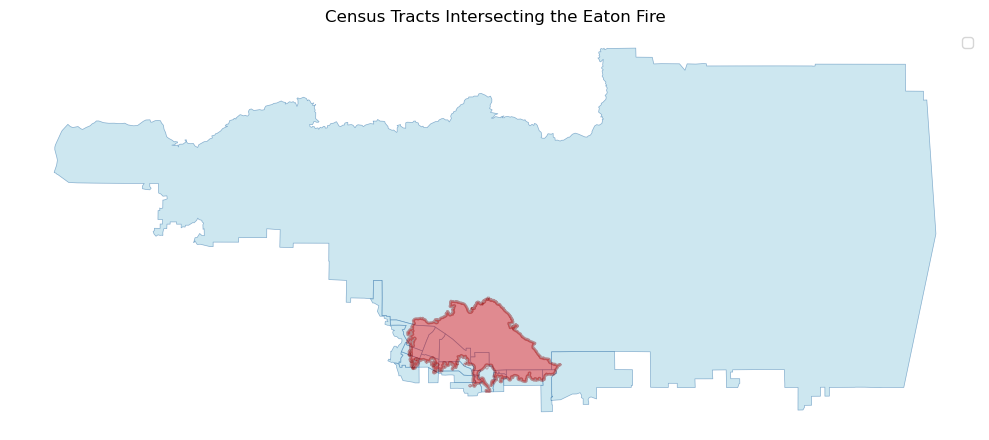

In [ ]:
# Plot census tract intersections with eaton fire
fig, ax = plt.subplots(1, 1, figsize=(10,10))

# Census tracts
eji_eaton.plot(ax=ax,
                color='lightblue',
                edgecolor='steelblue',
                linewidth=0.5,
                alpha=0.6,
                label='Census tracts')

# Eaton fire boundary with legend
eaton.boundary.plot(ax=ax,
                   color='red',
                   edgecolor='darkred',
                   linewidth=2,
                   alpha=0.4,
                   label='Eaton perimeter')

# Eaton fire interior
eaton.plot(ax=ax,
            color='red',
            edgecolor='darkred',
            linewidth=2,
            alpha=0.4,
            label='Eaton perimeter')


ax.set_title('Census Tracts Intersecting the Eaton Fire')
ax.legend()
ax.axis('off')
plt.tight_layout()

plt.show()

/var/folders/ym/4rcj1hsx32g1g4xxc3ynwllr0000gn/T/ipykernel_57487/2433728849.py:26: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


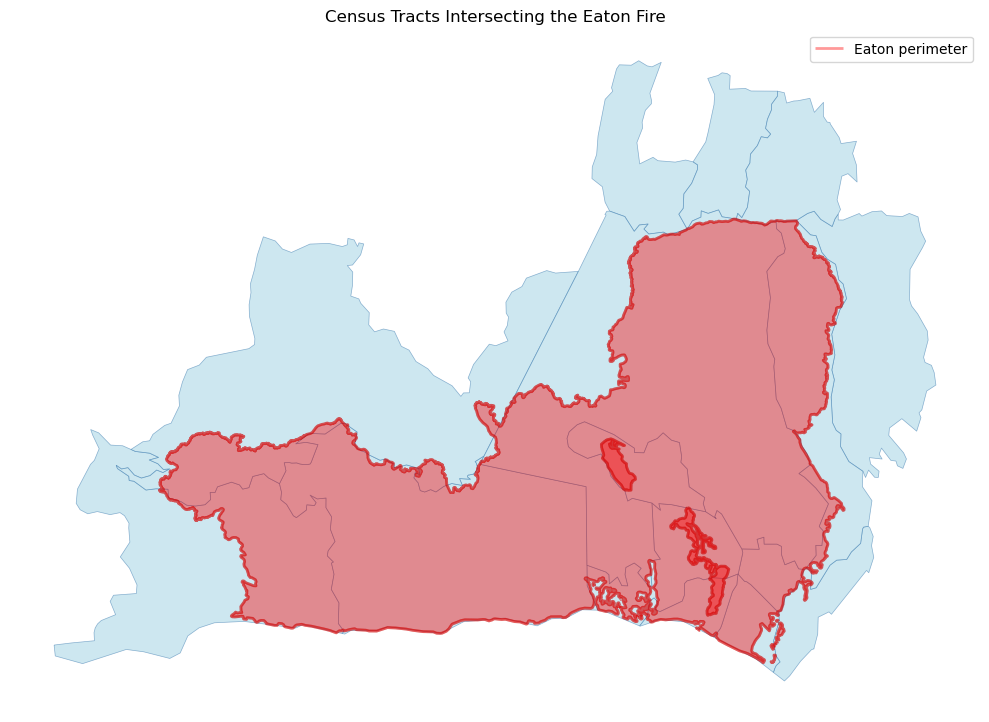

In [ ]:
# Plot census tract intersections with palisades fire
fig, ax = plt.subplots(1, 1, figsize=(10,10))

# Census tracts
eji_palisades.plot(ax=ax,
                    color='lightblue',
                    edgecolor='steelblue',
                    linewidth=0.5,
                    alpha=0.6,
                    label='Census tracts')

# Palisades fire boundary with legend
palisades.boundary.plot(ax=ax,
                    color='red',
                    edgecolor='darkred',
                    linewidth=2,
                    alpha=0.4,
                    label='Palisades perimeter')

# Palisades fire interior
palisades.plot(ax=ax,
                color='red',
                edgecolor='darkred',
                linewidth=2,
                alpha=0.4,
                label='Palisades perimeter')

ax.set_title('Census Tracts Intersecting the Palisades Fire')
ax.legend()
ax.axis('off')
plt.tight_layout()

plt.show()

## Polygon clipping

In [23]:
# Clip the census tracts to the Palisades fire perimeter
eji_palisades_clip = gpd.clip(eji_palisades, palisades)

# Clip the census tracts to the Eaton fire perimeter
eji_eaton_clip = gpd.clip(eji_eaton, eaton)

/var/folders/ym/4rcj1hsx32g1g4xxc3ynwllr0000gn/T/ipykernel_57487/1732832575.py:30: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


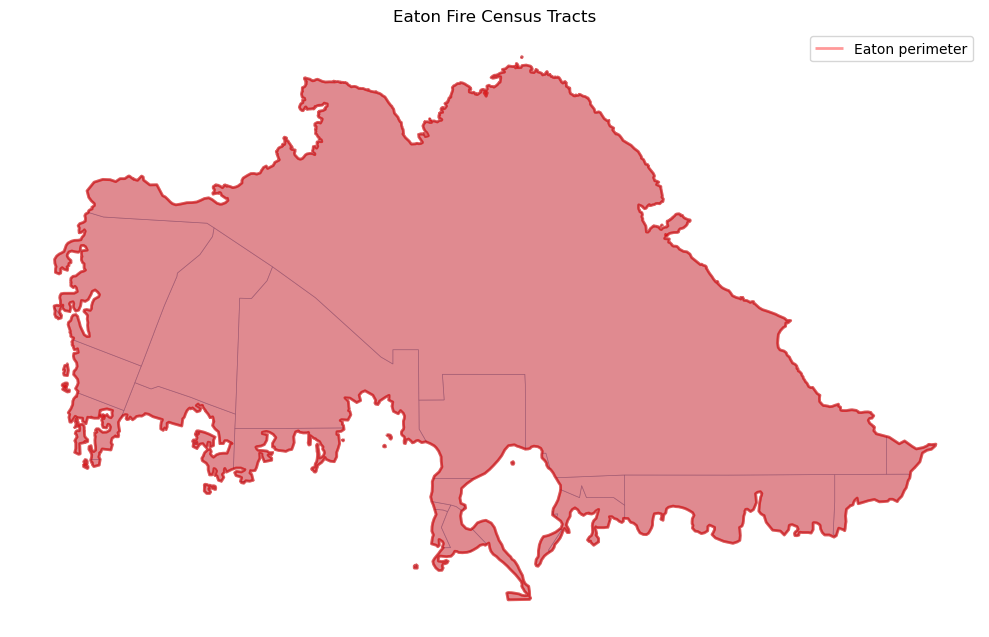

In [24]:
# Visualize the clipped census tracts with the fires
fig, ax = plt.subplots(1, 1, figsize=(10,10))

# Census tracts
eji_eaton_clip.plot(ax=ax,
                    color='lightblue',
                    edgecolor='steelblue',
                    linewidth=0.5,
                    alpha=0.6,
                    label='Census tracts')

# Eaton fire boundary with legend
eaton.boundary.plot(ax=ax,
                   color='red',
                   edgecolor='darkred',
                   linewidth=2,
                   alpha=0.4,
                   label='Eaton perimeter')

# Eaton fire interior
eaton.plot(ax=ax,
            color='red',
            edgecolor='darkred',
            linewidth=2,
            alpha=0.4,
            label='Eaton perimeter')


ax.set_title('Eaton Fire Census Tracts')
ax.legend()
ax.axis('off')
plt.tight_layout()

plt.show()

/var/folders/ym/4rcj1hsx32g1g4xxc3ynwllr0000gn/T/ipykernel_57487/3799687442.py:30: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


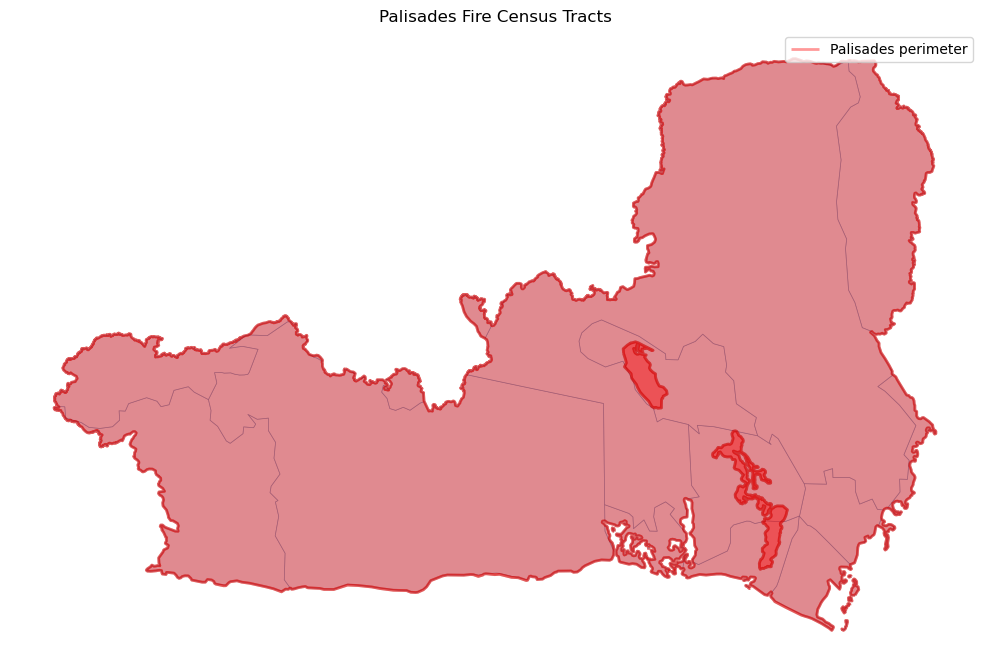

In [25]:
# Visualize the clipped census tracts with the fires
fig, ax = plt.subplots(1, 1, figsize=(10,10))

# Census tracts
eji_palisades_clip.plot(ax=ax,
                        color='lightblue',
                        edgecolor='steelblue',
                        linewidth=0.5,
                        alpha=0.6,
                        label='Census tracts')

# Palisades fire boundary with legend
palisades.boundary.plot(ax=ax,
                    color='red',
                    edgecolor='darkred',
                    linewidth=2,
                    alpha=0.4,
                    label='Palisades perimeter')

# Palisades fire interior
palisades.plot(ax=ax,
                color='red',
                edgecolor='darkred',
                linewidth=2,
                alpha=0.4,
                label='Palisades perimeter')


ax.set_title('Palisades Fire Census Tracts')
ax.legend()
ax.axis('off')
plt.tight_layout()

plt.show()

## Visualize fire perimeters with a basemap

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# ADD FIRE PERIMETERS: UPDATE FILL TRANSPARENCY AND COLOR

# ADD LEGEND OR ANNOTATION TO IDENTIFY EACH FIRE

# Add basemap using contextily
# Call it after plotting the perimeters so it covers their extent,
# and pass the CRS of your perimeters so the tiles line up with them
ctx.add_basemap(ax, crs=UPDATE.crs, source=ctx.providers.Esri.WorldStreetMap)

# ADD TITLE

ax.axis('off')

plt.tight_layout()
plt.show()

## Visualize EJI data

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

# UPDATE WITH YOUR EJI VARIABLE FROM STEP 1
eji_variable = ''

# Find common min/max for legend range
vmin = min(palisades_tracts[eji_variable].min(), eaton_tracts[eji_variable].min())
vmax = max(palisades_tracts[eji_variable].max(), eaton_tracts[eji_variable].max())

# Plot Palisades census tracts
palisades_tracts.plot(
    column=eji_variable,
    vmin=vmin, vmax=vmax,
    legend=False,
    ax=ax1,
)
ax1.set_title('UPDATE TITLE')
ax1.axis('off')

# Plot Eaton census tracts
eaton_tracts.plot(
    column=eji_variable,
    vmin=vmin, vmax=vmax,
    legend=False,
    ax=ax2,
)
ax2.set_title('UPDATE TITLE')
ax2.axis('off')

# Add overall title
fig.suptitle('YOUR VARIABLE HERE - Fire Areas Comparison')

# Add shared colorbar at the bottom
sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin=vmin, vmax=vmax))
cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('YOUR VARIABLE HERE (WITH UNITS)')

plt.show()